<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/5.%20sequential%20models/2.%20RNN_timeseries_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Time series data With RNN

- we will the dataset from [chicago data portal](https://data.cityofchicago.org/Transportation/CTA-Ridership-Daily-Boarding-Totals/6iiy-9s97/about_data), it is the dataset shows systemwide boardings for both bus and rail services provided by Chicago Transit Authority (CTA) rom 2001.

In [64]:
import torch
import torch.nn as nn
import torch.nn.functional as G
import torch.optim as optim
import torchvision.transforms as T
from torch.utils.data import DataLoader
from torch.utils.data.dataset import Dataset


import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from tqdm.notebook import tqdm

import requests

## Load and analyse Dataset
- I downloaded the dataset from [ageron/data](https://github.com/ageron/data/blob/main/ridership/CTA_-_Ridership_-_Daily_Boarding_Totals.csv)(He is the author of the awesome book "Hands on ML from Oreilly")

In [65]:
# we'll use requests and pandas to import our dataset then convert to pytorch dataset

url = "https://raw.githubusercontent.com/ageron/data/refs/heads/main/ridership/CTA_-_Ridership_-_Daily_Boarding_Totals.csv"

df = pd.read_csv(url, engine = 'python')

In [66]:
df.head()

,service_date,day_type,bus,rail_boardings,total_rides
0,01/01/2001,U,297192,126455,423647
1,01/02/2001,W,780827,501952,1282779
2,01/03/2001,W,824923,536432,1361355
3,01/04/2001,W,870021,550011,1420032
4,01/05/2001,W,890426,557917,1448343


In [67]:
df.info()

"""
We can see that the datatypes for the service date should be changed to datatime
also we do not need the total column
"""

df['Date'] = pd.to_datetime(df['service_date'])
df.set_index('Date', inplace = True)
df.drop('service_date', axis = 1, inplace = True)
df.drop('total_rides', axis = 1, inplace = True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7701 entries, 0 to 7700
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   service_date    7701 non-null   object
 1   day_type        7701 non-null   object
 2   bus             7701 non-null   int64 
 3   rail_boardings  7701 non-null   int64 
 4   total_rides     7701 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 300.9+ KB
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 7701 entries, 2001-01-01 to 2021-11-30
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   day_type        7701 non-null   object
 1   bus             7701 non-null   int64 
 2   rail_boardings  7701 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 240.7+ KB


In [68]:
df.describe().style.format('{:.1f}')

,bus,rail_boardings
count,7701.0,7701.0
mean,752717.9,541333.8
std,262267.7,205312.5
min,80783.0,23544.0
25%,506929.0,355696.0
50%,834640.0,609325.0
75%,976022.0,710361.0
max,1211992.0,1146516.0


In [69]:
pd.unique(df.loc[:,'day_type'].values)

array(['U', 'W', 'A'], dtype=object)

In [70]:
print(f"The start and end dates in the dataset:{df.index[0], df.index[-1]}")

The start and end dates in the dataset:(Timestamp('2001-01-01 00:00:00'), Timestamp('2021-11-30 00:00:00'))


- we have 5 columns in our dataset:
 0.   service_date    : Date
 1.   day_type        : type of day [W: weekday, A: Saturday. U: Sunday or Holiday]
 2.   bus             : No of passengers travelled from buses
 3.   rail_boardings  : rail passengers
 4.   total_rides     : Total passengers

- No Nan or missing values in our dataset.

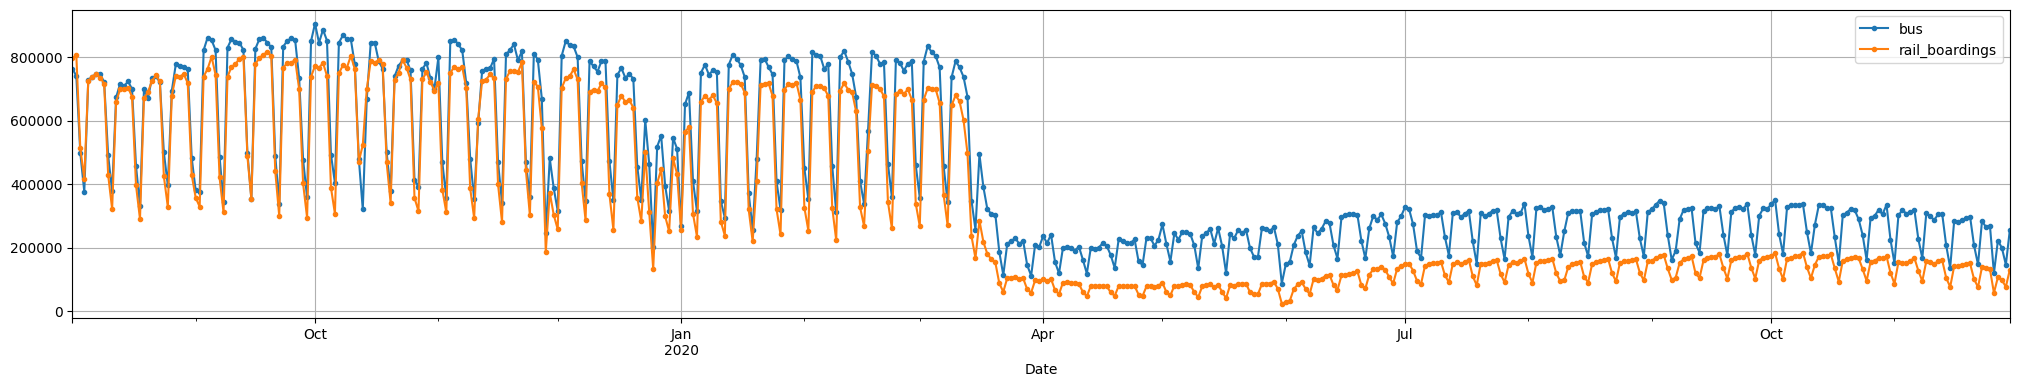

In [71]:
# Let us plot two months of the data to see any patterns:
df = df.sort_index()
df['2019-08':'2020-11'].plot(grid = True, marker = '.', figsize = (25,4))
plt.show()

- we can there is a clear pattern in our dataset which we will try to make an RNN learn to forecast
- The difference in rail and bus passengers around 2020 april is probably dur to covid19 pandamic. we cannot expect our model to predict this trend so I will only be using the data untill Jan 2020

## Make Pytorch dataset

In [72]:
class CTADataset(Dataset):
  def __init__(self, url, day_range, split_date, chop_dates , train_test = "train"):
    '''
    url: our dataset csv url
    day_range : Number of days we input to the model (we use this to chunk out dataset into required number of days per step)
    split_date: The date where we split the dataset in to train and test dataset
    train_test : defined it we want train or test dataset.
    '''
    #load the datset
    df = pd.read_csv(url, engine = 'python')
    #set the Date column as index
    df.columns = ['date', 'day_type', 'bus', 'rail', 'total'] # we can shorten the names
    df['date'] = pd.to_datetime(df['date'])
    df.set_index('date', inplace = True)
    df = df.sort_index()
    df.drop('total', axis = 1, inplace=True)
    df.drop('day_type', axis = 1, inplace=True)
    df.drop_duplicates()

    #chop the dataset
    df = df.loc[chop_dates[0]:chop_dates[-1]]

    #normalise our data

    mean = df.mean()
    std = df.std()
    df = (df-mean)/std

    self.mean = torch.tensor(mean.to_numpy(), dtype=torch.float32).reshape(1, -1)
    self.std = torch.tensor(std.to_numpy(),dtype=torch.float32).reshape(1, -1)

    #we can add the functionality to split the data into train and test:
    if train_test == 'train':
      self.dataset = df[df.index < split_date]
    elif train_test == 'test':
      self.dataset = df[df.index >= split_date]
    else:
      raise ValueError('train_test must be train or test')

    self.day_range = day_range

  def __getitem__(self, index):

    end_index = index + self.day_range
    #print(index, end_index)
    current_chunk = self.dataset.iloc[index:end_index]

    day_tensor = torch.LongTensor(current_chunk.index.day.to_numpy())
    month_tensor = torch.LongTensor(current_chunk.index.month.to_numpy())
    data_values = torch.FloatTensor(current_chunk.values)

    return day_tensor,month_tensor, data_values

  def __len__(self):
    return len(self.dataset) - self.day_range

In [73]:
# Let us define the values that we want to pass to the dataset and dataloaders
dataset_url = "https://raw.githubusercontent.com/ageron/data/refs/heads/main/ridership/CTA_-_Ridership_-_Daily_Boarding_Totals.csv"

#Number of days in Input sequence
day_range = 15

# No of days our RNN takes as Input
days_in = 14

#Meaning we predict the next day based on the 14 days input and feed the outpur back to the sequence and predict the next day!!
# Note that day_range has to be always bigger than the days_in.
# we will use these two variables during looping in our training and loss calculation
# we initize our dataloader with day_range datapoints and RNN takes days_in inputs. we use the last timestep in dataloader each time to compute loss

lr = 0.0001
nepochs = 500
batch_size = 32

#We can load our datasets train and test
split_date  = "2018-01-01"

chop_dates = ('2010-01-01','2020-01-01')

train_dataset = CTADataset(url = dataset_url, day_range = day_range, split_date = split_date, chop_dates=chop_dates, train_test='train')

test_dataset = CTADataset(url = dataset_url, day_range = day_range, split_date = split_date, chop_dates=chop_dates, train_test='test')

In [74]:
print(f'The length of the train dataset is : {len(train_dataset)}')
print(f'The length of the test dataset is : {len(test_dataset)}')

The length of the train dataset is : 2969
The length of the test dataset is : 716


In [75]:
# Now we can define our data loaders
train_data_loader = DataLoader(dataset = train_dataset, batch_size = batch_size, shuffle = True, drop_last=True)
test_data_loader = DataLoader(dataset = test_dataset, batch_size = 32, shuffle = True, drop_last = True)

In [76]:
for i, (day, month, data_seq) in enumerate(tqdm(train_data_loader, desc="Training", leave=False)):

  print(day.shape)
  print(month.shape)
  print(data_seq.shape)   # total sequence length [15]
  in_seq = data_seq[:,:days_in]  #our input sequence for every batch [14]
  print(in_seq.shape)
  break

Training:   0%|          | 0/92 [00:00<?, ?it/s]

torch.Size([32, 15])
torch.Size([32, 15])
torch.Size([32, 15, 2])
torch.Size([32, 14, 2])


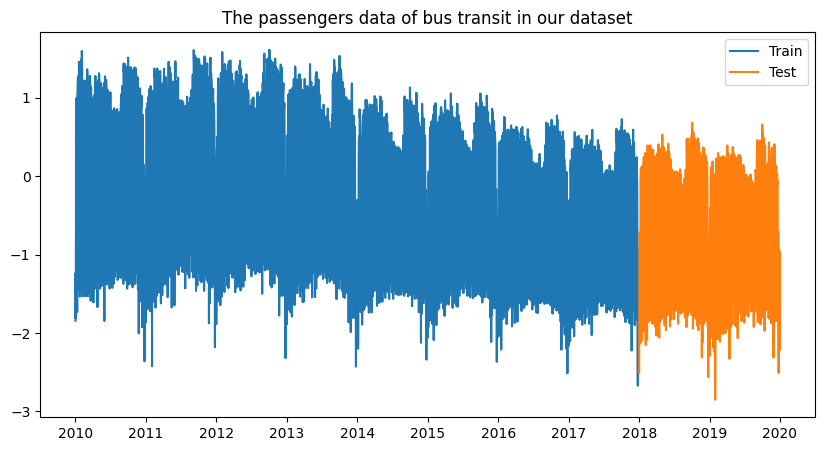

In [77]:
# Our train and test datasets of Dataset class has two time series 0: Bus, 1:train

plt.figure(figsize=(10, 5))
plt.title("The passengers data of bus transit in our dataset")

plt.plot(train_dataset.dataset.index, train_dataset.dataset.values[:, 0])
plt.plot(test_dataset.dataset.index, test_dataset.dataset.values[:, 0])

plt.legend(["Train", "Test"])

## Create Our simple RNN

In [78]:
class SimpleRNN(nn.Module):
  def __init__(self, input_size, hidden_size, output_size, num_layers = 1):
    super(SimpleRNN, self).__init__()

    self.rnn = nn.RNN(input_size = input_size,
                      hidden_size = hidden_size,
                      num_layers=num_layers,
                      batch_first = True)

    #define our outpur layer
    self.out = nn.Linear(hidden_size, output_size)

  def forward(self, x):

    #outputs predictions for each batch and final hidden state
    rnn_out, h_n = self.rnn(x)

    last_output = rnn_out[:,-1,:]

    #pass through our final layer
    out = self.out(last_output)

    return out, h_n




In [79]:
# define if there is a gpu available
gpu_id = 0
device = torch.device(gpu_id if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [80]:
hidden_size = 128

passenger_rnn = SimpleRNN(input_size = train_dataset.dataset.shape[-1], hidden_size = hidden_size, output_size = 2)
passenger_rnn.to(device)
passenger_rnn

SimpleRNN(
  (rnn): RNN(2, 128, batch_first=True)
  (out): Linear(in_features=128, out_features=2, bias=True)
)

In [81]:
# Let's see how many Parameters our Model has!
num_model_params = 0
for param in passenger_rnn.parameters():
    num_model_params += param.flatten().shape[0]
print(f"shape of the paramerts is : {param.shape}")
print(f"number of trainiable parameters in our model is : {num_model_params}")

"""
nn.RNN layer:
  - 128*14(weights) + 128(bias)
  - 128*128(weights) + 128(bias)
nn.Linear:
  - 128*2(weights) + 2(bias)
"""

shape of the paramerts is : torch.Size([2])
number of trainiable parameters in our model is : 17154


'\nnn.RNN layer: \n  - 128*14(weights) + 128(bias)\n  - 128*128(weights) + 128(bias)\nnn.Linear:\n  - 128*2(weights) + 2(bias)\n'

## Train our RNN

In [82]:
loss_fn = nn.MSELoss()
optimizer = optim.Adam(passenger_rnn.parameters(), lr = lr)
train_loss_logger = []

In [84]:
for epoch in tqdm(range(nepochs), desc = "Epochs", leave = False):
  #set the model to training mode
  passenger_rnn.train()

  #now wa can iterate over each batch in the dataset
  for day, month, dataseq in tqdm(train_data_loader, desc = "training", leave = False):
    # Extract our input data seq
    in_seq = dataseq[:, :days_in].to(device)

    #initiate the batch loss
    loss = 0

    #iterate over each time step in our dataseq
    for i in range(day_range-days_in):    #if we decide to predict more that 1 day Ex: 2 or 3 days forecasting
      #extract the target for loss calculation
      target_seq_block = dataseq[:, i+days_in].to(device)

      #predict our next day
      prediction , hidden = passenger_rnn(in_seq)

      #calculate the loss
      loss += loss_fn(prediction, target_seq_block)


      #we can update the input sequence by removing the oldest prediction and update it with new prediction
      in_seq = torch.cat((in_seq[:,1:,:], prediction.unsqueeze(1).detach()),1)  #concatenate (in_seq) with (unsqueezed prediction at dim 1) at dim 1 for both tensors

    loss /= i + 1

    #start the back propogation for each batch
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    #log the training loss now
    train_loss_logger.append(loss.item())

Epochs:   0%|          | 0/500 [00:00<?, ?it/s]

training:   0%|          | 0/92 [00:00<?, ?it/s]

training:   0%|          | 0/92 [00:00<?, ?it/s]

training:   0%|          | 0/92 [00:00<?, ?it/s]

training:   0%|          | 0/92 [00:00<?, ?it/s]

training:   0%|          | 0/92 [00:00<?, ?it/s]

... (491 outputs left out)

training:   0%|          | 0/92 [00:00<?, ?it/s]

training:   0%|          | 0/92 [00:00<?, ?it/s]

training:   0%|          | 0/92 [00:00<?, ?it/s]

training:   0%|          | 0/92 [00:00<?, ?it/s]

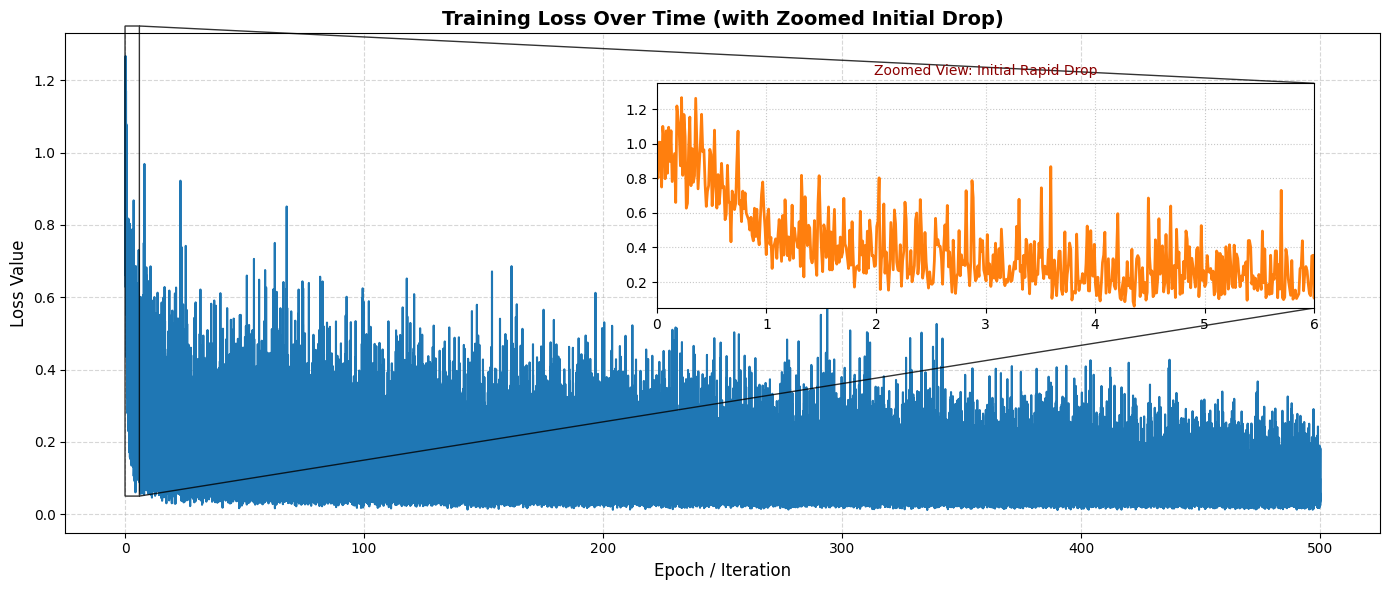

In [111]:
# I got this code from Gemini to zoom the plot of the loss curve
x_axis = np.linspace(0, nepochs, len(train_loss_logger))
fig, ax = plt.subplots(figsize=(14, 6))

# 1. Plot the main loss curve
ax.plot(x_axis, train_loss_logger, color="tab:blue", label="Training Loss")
ax.set_title(
    "Training Loss Over Time (with Zoomed Initial Drop)",
    fontsize=14,
    fontweight="bold",
)
ax.set_xlabel("Epoch / Iteration", fontsize=12)
ax.set_ylabel("Loss Value", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)

# 2. Define the region you want to zoom into (e.g., the first 30 epochs where the drop happens)
x1, x2 = 0, 6
y1, y2 = 0.05, 1.35

# 3. Create an inset axes (the zoomed-in box)
# loc='upper right' or custom [left, bottom, width, height] coordinates in figure fraction
axins = ax.inset_axes(
    [0.45, 0.45, 0.5, 0.45],  # [x0, y0, width, height] relative to main axes
    xlim=(x1, x2),
    ylim=(y1, y2),
)

# 4. Plot the exact same data inside the zoom window
axins.plot(x_axis, train_loss_logger, color="tab:orange", linewidth=2)
axins.set_title("Zoomed View: Initial Rapid Drop", fontsize=10, color="darkred")
axins.grid(True, linestyle=":", alpha=0.7)

# 5. Automatically draw a rectangle on the main plot and connect it to the inset with lines!
ax.indicate_inset_zoom(axins, edgecolor="black", alpha=0.8)

plt.tight_layout()
plt.show()

- our loss curve is pretty bumpy and the training lossif still decreasing. We could benifit from more iterations and
- a bigger batch size would flatten the fluctuations a little.
- Also, we used a simple RNN, increasing the complexity of our model can help converg the loss faster.

## Evaluating out trained model usign test data

- we can use the test data feed the first 14 days to the model and let it predict auto regressively to match the length of the test_data_set

In [87]:
# we can start by converting the target dataset values into tensor and use the first 14 days to start the predictions
data_tensor = torch.FloatTensor(test_dataset.dataset.values).to(device)

log_predictions = []

passenger_rnn.eval()

with torch.no_grad():
  #get the first 14 days and match the shape to expected shape for the model
  in_seq = data_tensor[:days_in, :].unsqueeze(0).to(device)

  for i in range(data_tensor.shape[0] - days_in):  #to match the target dataset length
    data_pred , _ = passenger_rnn(in_seq)

    #log the predictions for plotting
    log_predictions.append(data_pred.cpu())

    #update the in_seq with the new prediction and remove the oldest prediction
    in_seq = torch.cat((in_seq[:,1:, :], data_pred.unsqueeze(1)), 1)

# Concatenate the logged predictions to a single tensor and un normalise the predictions and test data and plot the resutls
pred_cat = torch.cat(log_predictions)

#unnormalise
un_norm_predictions = (pred_cat * test_dataset.std) + test_dataset.mean
un_norm_targets = (data_tensor.cpu() * test_dataset.std) + test_dataset.mean

In [89]:
print(len(un_norm_predictions))
print(len(un_norm_targets))
#To match the lengths, remove the first 14 days of data from unnormalised targets

un_norm_targets = un_norm_targets[days_in:]
print(len(un_norm_targets))

717
731
717


In [ ]:
test_mse = (un_norm_targets - un_norm_predictions).pow(2).mean().item()
print("Test MSE value %.2f" % test_mse)

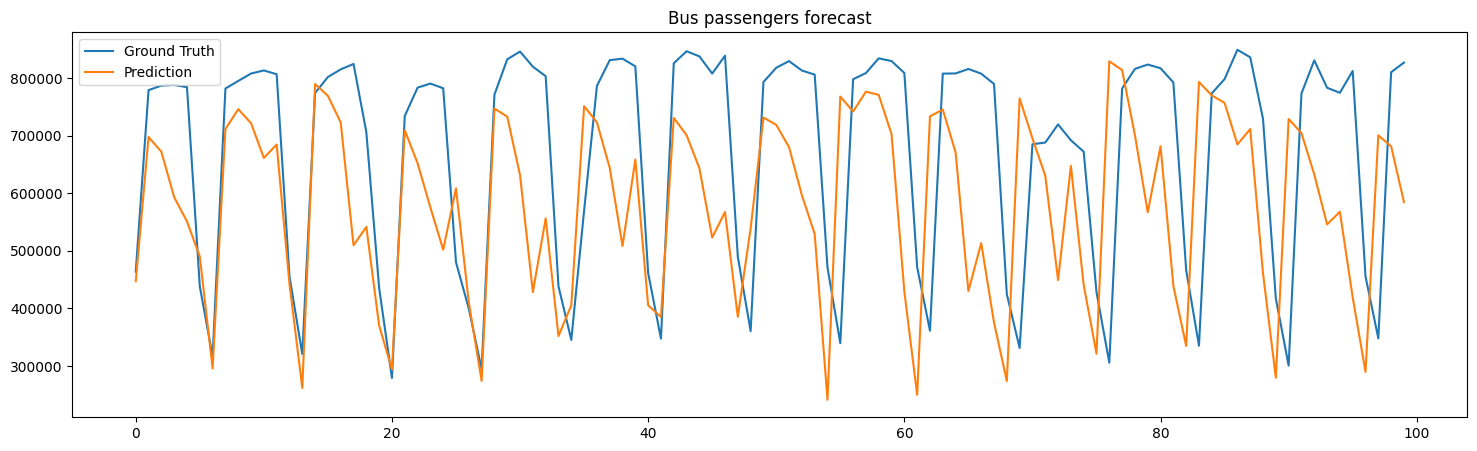

In [98]:
plt.figure(figsize=(18, 5))
plt.plot(un_norm_targets[:100, 0])
plt.plot(un_norm_predictions[:100, 0])
plt.title("Bus passengers forecast")

plt.legend(["Ground Truth", "Prediction"])

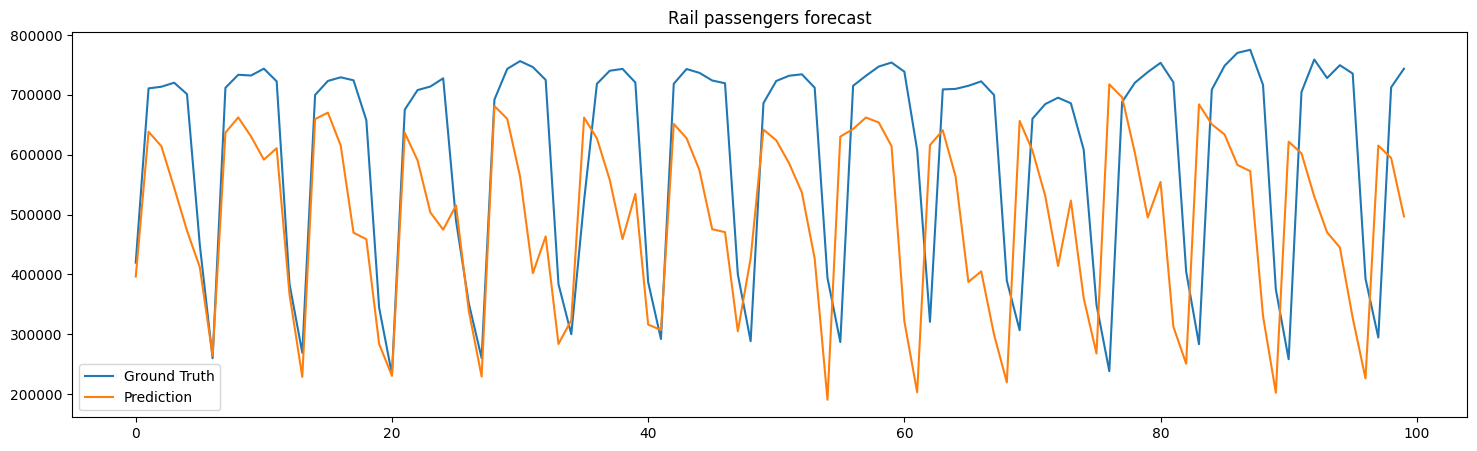

In [99]:
plt.figure(figsize=(18, 5))
plt.plot(un_norm_targets[:100, 1])
plt.plot(un_norm_predictions[:100, 1])
plt.title("Rail passengers forecast")

plt.legend(["Ground Truth", "Prediction"])